<a id="chapter-22"></a>

# Chapter 22 · Multi-Agent RL / 多智能体强化学习

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解 Markov game 与联合动作
- 认识非平稳性、合作与竞争
- 区分 independent learning 与 CTDE

**开始前最好已经会：**

- 掌握单智能体 Q-learning/actor-critic
- 理解联合概率与博弈收益
- 知道局部观测


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| What is multi-agent RL? | Markov game 与非平稳性 | 详细 |
| MAgent environment/install/random setup | 环境接口与随机 baseline | 源码路线 |
| DQN for tigers | 共享网络与 group experience | 详细 |
| Tiger collaboration | 团队奖励与协作 | 详细 |
| Training tigers and deer | 双群体同时学习 | 完整流程 |
| Battle environment | 竞争/self-play | 源码路线 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

当环境里的其他角色也在学习时，昨天有效的策略今天可能失效。多智能体 RL 的难点不是简单复制多个 DQN，而是学习对象本身在变化。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

每个智能体都在学习时，其他智能体的策略变化会让环境看起来非平稳。训练时可集中使用全局信息，执行时再让每个 agent 只用局部观测。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $a^1,\ldots,a^n$ | 所有 agent 的联合动作 | 共同决定转移和奖励 |
| $r_i$ | agent $i$ 的奖励 | 可共享、竞争或混合 |
| $o_i$ | agent $i$ 的局部观测 | 执行时通常只能看到它 |
| centralized critic | 训练时使用全局信息的评价器 | 缓解非平稳性 |
| CTDE | 集中训练、分散执行 | 训练/部署信息边界不同 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. Markov game 扩展了 MDP

转移依赖联合动作：

$$P(s'|s,a^1,\ldots,a^n)$$

agent $i$ 最大化自己的目标

$$J_i=\mathbb E\left[\sum_t\gamma^t r_i(s_t,a_t^1,\ldots,a_t^n)\right]$$

若所有 $r_i$ 相同是完全合作；若一方收益恰为另一方负数是零和；现实常是混合博弈。

### 2. 为什么 independent learning 非平稳

agent 1 看到的有效转移还取决于 agent 2 的策略：

$$P_{eff}(s'|s,a^1)=\sum_{a^2}\pi_2(a^2|o_2)P(s'|s,a^1,a^2)$$

当 $\pi_2$ 学习并变化时，$P_{eff}$ 也变化，破坏单智能体算法假设的固定环境。

### 3. CTDE 怎样帮助

训练 critic 时使用全局状态和联合动作：

$$Q_i(s,a^1,\ldots,a^n)$$

它能解释奖励究竟由谁的动作导致；执行 actor 时仍只输入 $o_i$，满足分散部署限制。必须严格防止训练可见信息泄漏进执行网络。

### 4. credit assignment

共享团队奖励告诉大家成败，却不说明哪个 agent 贡献最大。value decomposition、counterfactual baseline 等方法试图把团队价值分解为可学习的个体信用。


## 4. 手算一个最小例子


协调博弈：两 agent 都选 0 或都选 1 时各得 1，否则得 0。存在两个同样好的均衡 `(0,0)` 和 `(1,1)`。

独立 Q-learning 可能因早期随机波动收敛到任意一个均衡；若两个 agent 各自偏向不同动作，短期会互相得到 0，协调变得困难。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### Markov game

联合策略下 agent $i$ 的目标：
$$J_i(\pi_1,\ldots,\pi_n)=\mathbb E\left[\sum_t\gamma^t r_i(s_t,a_t^1,\ldots,a_t^n)\right]$$

Independent Q-learning 把其他 agent 当环境一部分；CTDE 的 centralized critic 可用联合状态/动作估计 $Q_i(s,a^1,\ldots,a^n)$，actor 执行时只用本地观测。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $Q_1(a^1),Q_2(a^2)$ | `q1`, `q2` | 两个独立 learner 的估计 |
| $a^1,a^2$ | `a1`, `a2` | 各自 epsilon-greedy 动作 |
| 共享 $r$ | `float(a1 == a2)` | 协调成功奖励 |
| 独立更新 | `q1[a1] += ...`, `q2[a2] += ...` | 彼此当作环境 |
| 联合信息 | centralized critic 输入 | 示例未实现，项目/扩展继续学习 |

**从公式过渡到代码时：**这个协调博弈展示多个同样最优均衡：双方动作相同时得 1，否则得 0。独立 Q-learning 的结果会受探索与随机种子影响。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import numpy as np

rng = np.random.default_rng(3)
q1 = np.zeros(2)
q2 = np.zeros(2)
alpha, epsilon = 0.1, 0.1

for _ in range(3000):
    a1 = rng.integers(2) if rng.random() < epsilon else q1.argmax()
    a2 = rng.integers(2) if rng.random() < epsilon else q2.argmax()
    reward = float(a1 == a2)
    q1[a1] += alpha * (reward - q1[a1])
    q2[a2] += alpha * (reward - q2[a2])

print("agent 1 Q:", np.round(q1, 3), "policy:", q1.argmax())
print("agent 2 Q:", np.round(q2, 3), "policy:", q2.argmax())


agent 1 Q: [0.997 0.172] policy: 0
agent 2 Q: [0.925 0.227] policy: 0


### 怎样读运行结果

两个 Q 表最终应偏向同一个动作，但多个 seed 可能选择不同均衡。这个现象不是 bug，而是对称博弈的多均衡性质。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
parallel env.reset → dict(agent_id → observation)
按 agent group 选择共享 policy/network
每步为所有存活 agent 生成 action dict
env.step(action_dict) → obs/reward/termination/truncation dicts
experience source 按 agent_id 维护各自 n-step deque
写入 experience 时附带 group；死亡 agent 正确结束轨迹
从 buffer 按 group 过滤 batch，分别更新各网络
定期在固定对手池评估捕获数、存活数、团队回报
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# 协调博弈的联合 payoff 表：对角线为共享奖励 1。
payoff = np.eye(2)
print("joint payoff:\n", payoff)
for a1 in range(2):
    for a2 in range(2):
        print((a1, a2), "reward", payoff[a1, a2])
assert payoff[0, 0] == payoff[1, 1] == 1


joint payoff:
 [[1. 0.]
 [0. 1.]]
(0, 0) reward 1.0
(0, 1) reward 0.0
(1, 0) reward 0.0
(1, 1) reward 1.0


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`data.py`](../../Chapter22/lib/data.py) | `ForestEnv`, `BattleEnv`, `MAgentExperienceSourceFirstLast` | 环境和多 agent 经验核心 |
| [`model.py`](../../Chapter22/lib/model.py) | `DQNModel`, `unpack_batch`, `calc_loss_dqn` | 共享 DQN 与 group batch |
| [`forest_random.py`](../../Chapter22/forest_random.py) | 随机 baseline | 先理解 observation/action dict |
| [`forest_tigers_dqn.py`](../../Chapter22/forest_tigers_dqn.py) | 单群体学习 | tigers 对固定 deer |
| [`forest_both_dqn.py`](../../Chapter22/forest_both_dqn.py) | 双群体学习 | 两个网络和 batch filter |
| [`battle_dqn.py`](../../Chapter22/battle_dqn.py) | battle/self-play | 对手非平稳与评估 |

<details>
<summary>为什么按这个顺序读</summary>

`MAgentExperienceSourceFirstLast` 是本章关键：它为每个 agent id 维护独立历史，同时 agent 会出生/死亡，不能按数组位置假设身份稳定。`agent_group` 决定由哪个 policy 产生动作，经验中的 group 用于训练时过滤。双群体脚本应检查两个 optimizer、target net 和 replay 是否正确隔离；评估对手要冻结，避免测试环境也非平稳。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**两个独立 Q-learning agent 的协作回报

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


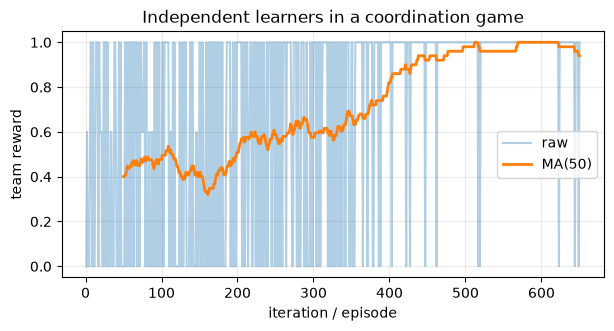

policies: 1 1 last-50 reward: 0.94


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(22)
q1, q2, rewards = np.zeros(2), np.zeros(2), []
# 协调博弈：(1,1) 得 1；(0,0) 得 .6；不一致得 0。
payoff = np.array([[.6, 0.0], [0.0, 1.0]])
for episode in range(650):
    eps = max(.03, 1 - episode/450)
    a1 = rng.integers(2) if rng.random() < eps else np.argmax(q1)
    a2 = rng.integers(2) if rng.random() < eps else np.argmax(q2)
    reward = payoff[a1, a2]
    q1[a1] += .08 * (reward - q1[a1]); q2[a2] += .08 * (reward - q2[a2])
    rewards.append(reward)

plot_curve(rewards, "Independent learners in a coordination game", "team reward", window=50)
print("policies:", q1.argmax(), q2.argmax(), "last-50 reward:", np.mean(rewards[-50:]))


### 曲线怎么读

移动平均上升表示形成协作，但独立学习可能收敛到次优的 (0,0)。多智能体曲线必须跨种子报告：环境对每个 agent 都因其他 agent 学习而非平稳。

### 调参过程：一次只改变一个因素

- 先训练随机/固定对手 baseline，再训练双方学习。
- 分别记录 team reward、各 agent reward、胜率和策略熵。
- 调 epsilon/对手池/target sync 时用多种子统计收敛到不同均衡的比例。

### 失败案例复盘

- 把其他 agent 当作静态环境，replay 中旧数据严重过时。
- 只报告最好种子，隐藏收敛到次优均衡的概率。
- 共享奖励索引或 agent id 处理错误，经验归属错位。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 明确 reward 是共享、个体还是混合，否则“合作”只是口号。
- 评估要固定对手池并覆盖不同强度，避免只会打当前对手。
- 并行环境中 agent id、alive mask、padding 最容易造成错位。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把不协调奖励改为 -1，比较学习速度；用多个 seed 观察最终选择 0 还是 1。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

不协调奖励改为 -1 后，错误配对惩罚更强，可能加快已有偏好的一致化，也可能让早期噪声更难恢复。多个 seed 最终可能落在 `(0,0)` 或 `(1,1)`，两者都是对称最优均衡；应报告协调成功率而非把某个动作编号当唯一答案。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 联合动作共同决定转移与奖励。
- 其他 agent 学习会造成非平稳性。
- CTDE 训练时看全局、执行时只看局部。
- 多智能体评估必须覆盖不同队友、对手和随机种子。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**为什么不能直接把 centralized critic 的全局状态也喂给执行 actor？independent Q-learning 为什么仍可能在简单任务有效？

<details>
<summary>展开答案</summary>

部署时单个 agent 往往拿不到全局信息，这会造成训练/执行不一致。简单任务中其他策略变化有限、共享奖励清晰时，独立学习仍可能近似有效。
</details>


## 17. 与前后章节连接

这是全书终点：MDP 被扩展为 Markov game，但回报、价值、bootstrap、函数逼近、replay 和策略优化仍是前面章节建立的同一套语言。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

value decomposition（VDN/QMIX）、self-play、population-based training、opponent modeling 与 communication learning 是常见扩展。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-22) · [← 学习索引](../README.md)
